In [1]:
# Standard imports
import sys
import pathlib

# Third party imports
import numpy as np
from scipy.optimize import fsolve
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Internal imports
sys.path.append('..')
from rate import q_exact_full
from rate import q_approx_full

In [2]:
# set plot style
%matplotlib widget
plt.style.use('plot_style.txt')

# output path for figures 
output_path = pathlib.Path("/home/jonas/shared/Work/SSeep2026/Figures")

In [3]:
# clogging layer
beds = [(0.1, 1e-8), (0.1, 1e-7), (1, 1e-8), (1, 1e-7)]
colors = ["#217faab3", "#5539d1b3", "#cf7826b3", "#b92c22b3"]

# aquifer
aq_cond = 1e-2 / (24 * 3600) * 10**2.808
aq_scale = 1e-2 / 10**-1.453
aq_shape = 10**0.502

In [4]:
def calibrate_cl_cond(stage, cl_cond, cl_th, aq_cond, aq_scale, aq_shape):

    q_ex = q_exact_full(stage, cl_cond, cl_th, aq_cond, aq_scale, aq_shape,
                        'vGM')

    def f(x):
        q_ap = q_approx_full(stage, x, cl_th, aq_cond=aq_cond,
                             aq_scale=aq_scale, aq_shape=aq_shape, aq_para='vGM')
        return q_ap - q_ex

    cal_cl_cond, _, _, _ = fsolve(f, cl_cond, full_output=True,)

    return cal_cl_cond

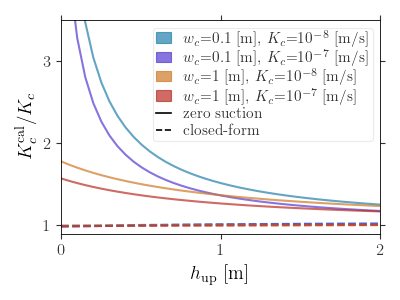

In [20]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.spines["top"].set_visible(True)
ax.spines["right"].set_visible(True)
ax.tick_params(top=True, right=True)
ax.minorticks_off()

for i, (wc, Kc) in enumerate(beds):
        # sand
        hc = wc * (aq_cond / Kc - 1)
        stage = np.linspace(0, min(hc, 5), 100)
        q_ex = q_exact_full(stage, Kc, wc, aq_cond, aq_scale, aq_shape, 'vGM')
        Kc_cal = wc * q_ex / (wc + stage)
        ax.plot(stage, Kc_cal / Kc, ls='-', lw=1.5, c=colors[i])

        Kc_cal = np.array([calibrate_cl_cond(h, Kc, wc, aq_cond, aq_scale, aq_shape) for h in stage])
        ax.plot(stage, Kc_cal / Kc, ls='--', lw=1.5, c=colors[i])

#ax.axhline(1, ls='-', lw=1, c='k')


# layout
ax.set_xlabel('$h_\\mathrm{up}$ [m]', labelpad=5)
ax.set_ylabel('$K_c^\\mathrm{cal} / K_c$', labelpad=5)
ax.set_xlim(xmin=0, xmax=2)
ax.set_ylim(ymin=0.9, ymax=3.5)

ax.set_xticks([0, 1, 2])
ax.set_yticks([1, 2, 3])


legend = [Patch(color=colors[0], label='$w_c{=}0.1$ [m], $K_c{=}10^{-8}$ [m/s]'),
          Patch(color=colors[1], label='$w_c{=}0.1$ [m], $K_c{=}10^{-7}$ [m/s]'),
          Patch(color=colors[2], label='$w_c{=}1$ [m], $K_c{=}10^{-8}$ [m/s]'),
          Patch(color=colors[3], label='$w_c{=}1$ [m], $K_c{=}10^{-7}$ [m/s]'),
          Line2D([0], [0], ls='-', color='k', label='zero suction'),
          Line2D([0], [0], ls='--', color='k', label='closed-form')]


plt.legend(handles=legend, fontsize=11, handlelength=1,
           labelspacing=0.2, handletextpad=0.8,         
           loc='upper right', ncols=1)

plt.tight_layout()
plt.savefig(output_path / 'conductance_calibration.pdf')